# PENDULUM

In [1]:
from matplotlib import pyplot as plt
import numpy as np

Tests:

No driving and damping:

1) Small angle approximation, get the period of a linear harmonic oscillator and verify energy conservation.

2) Non-linear oscillator, get the period with numerical integration and verify energy conservation.

Driving and damping:


1) Small angle approximation, get damping regimes of a linear harmonic oscillator.

2) Small angle approximation, compare with analytical damped + driven oscillator.

3) Non-linear oscillator, study chaos. Phase plot + period doubling with Feigenbaum delta + Lyapnov exponent



In [15]:
g  = 9.8
L = 9.8
w = np.sqrt(g/L)
m = 1.


#period of a non-linear pendulum
#calc_P = lambda th0: 4*(1/w)*np.trapz( 1/np.sqrt(1. - np.sin(th0/2.)**2.*np.sin(np.linspace(0, np.pi/2.,100))**2.), np.linspace(0, np.pi/2.,100) )



#trapezoidal method
def calc_P(th0):
    h = 0.001
    th = np.linspace(0, np.pi/2, int((np.pi/2)/h + 1))
    integrand = 4*(1/w)*1/np.sqrt(1. - np.sin(th0/2.)**2.*np.sin(th)**2.)
    result = (h/2)*(integrand[0] + 2*np.sum(integrand[1:-1]) + integrand[-1])
    return result

class pendulum(): 
    def __init__(self, m, w, L, th0, tmax, b, F, wext):
        #natural frequency which can never change
        self.w = w
        self.mass = m
        self.L = L

        if F == 0:
            self.t = np.linspace(0., tmax, int(tmax/0.001 + 1))
            self.dt = self.t[1] - self.t[0]
        else:
            self.t = np.linspace(0., tmax, int(tmax/(0.01*2*np.pi/wext) + 1))
            self.dt = self.t[1] - self.t[0]

            #use tmax =  D driving periods for pincare section
            #100 points per period. total = 100D points
 
        #initial parameters
        self.th = np.zeros(len(self.t))
        self.th[0] = th0

        self.v = np.zeros(len(self.t))
        self.v[0] = 0.

        self.x = self.L*np.sin(self.th)
        self.y = self.L*(1. - np.cos(self.th))
        self.E = (1.0/2.0)*self.mass*(self.v*self.L)**2.0 + self.mass*g*self.y

        self.b = b
        self.F = F
        self.wext = wext
       

    def a(self,v,th,t):
        return -self.b*v - self.w**2.0*np.sin(th) + self.F*np.cos(self.wext*t)
    
    def RK4(self, v, th, t):
        vk1 = self.dt*self.a(v,th,t)
        thk1 = self.dt*v

        vd = v + vk1/2.0
        thd = th + thk1/2.0
        td = t + self.dt/2.0

        vk2 = self.dt*self.a(vd,thd,td)
        thk2 = self.dt*vd

        vd = v + vk2/2.0
        thd = th + thk2/2.0
        td = t + self.dt/2.0

        vk3 = self.dt*self.a(vd,thd,td)
        thk3 = self.dt*vd

        vd = v + vk3
        thd = th + thk3
        td = t + self.dt

        vk4 = self.dt*self.a(vd,thd,td)
        thk4 = self.dt*vd

        new_th = th + (1.0/6.0)*(thk1 + 2.0*thk2 + 2.0*thk3 + thk4)
        if new_th>np.pi:
            new_th = new_th - 2*np.pi
        elif new_th<-np.pi:
            new_th = new_th + 2*np.pi

        return v + (1.0/6.0)*(vk1 + 2.0*vk2 + 2.0*vk3 + vk4), new_th
    
    def TE(self):
        for i in range(0, len(self.t)-1):
            self.v[i+1], self.th[i+1] = self.RK4(self.v[i], self.th[i], self.t[i])

        self.x = L*np.sin(self.th)
        self.y = self.L*(1. - np.cos(self.th))
        self.E = (1.0/2.0)*self.mass*(L*self.v)**2.0 + self.mass*g*self.y
        


## COMPARING LINEAR VERSUS NON-LINEAR 

In [16]:
pendu_1 = pendulum(m, w, L, 0.01, calc_P(0.01), 0., 0., 0.)

pendu_2 = pendulum(m, w, L, np.pi/3, calc_P(np.pi/3), 0., 0., 0.)

In [17]:
pendu_1.TE()

pendu_2.TE()

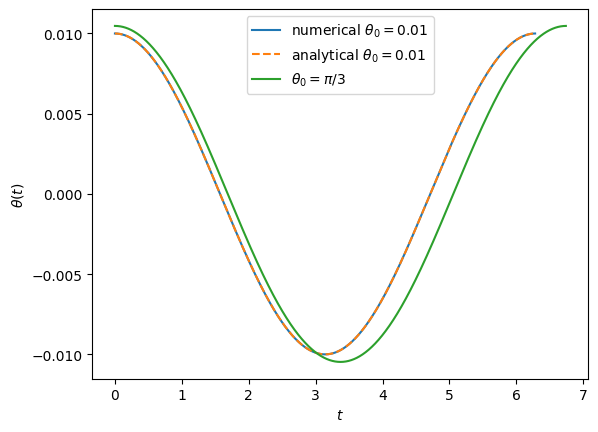

In [18]:
plt.plot(pendu_1.t, pendu_1.th, label ='numerical '+r'$\theta_0 = 0.01$')
plt.plot(pendu_1.t, 0.01*np.cos(w*pendu_1.t), label ='analytical '+r'$\theta_0 = 0.01$', linestyle='dashed')
plt.plot(pendu_2.t, pendu_2.th/100, label =r'$\theta_0 = \pi/3$') #multiply by 100 to see on same plot
plt.xlabel(r'$t$')
plt.ylabel(r'$\theta(t)$')
plt.legend()
plt.show()

C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_13808\923426332.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.plot(pendu_1.t, np.log10(np.abs(pendu_1.E - pendu_1.E[0])), label =r'$\theta_0 = 0.01$')
C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_13808\923426332.py:2: RuntimeWarning: divide by zero encountered in log10
  plt.plot(pendu_2.t, np.log10(np.abs(pendu_2.E - pendu_2.E[0])), label =r'$\theta_0 = \pi/3$')


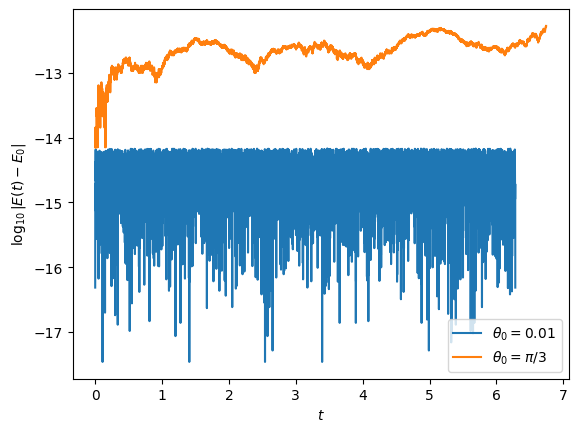

In [104]:
plt.plot(pendu_1.t, np.log10(np.abs(pendu_1.E - pendu_1.E[0])), label =r'$\theta_0 = 0.01$')
plt.plot(pendu_2.t, np.log10(np.abs(pendu_2.E - pendu_2.E[0])), label =r'$\theta_0 = \pi/3$')
plt.xlabel(r'$t$')
plt.ylabel(r'$\log_{10}|E(t) - E_0|$')
plt.legend()
plt.show()

## DAMPED AND DRIVEN

In [108]:
pendu_3 = pendulum(m, w, L, 0.01, 2*calc_P(0.01), 0.5*2.*w, 0., 0.)

pendu_4 = pendulum(m, w, L, 0.01, 2*calc_P(0.01), 1.0*2.*w, 0., 0.)

pendu_5 = pendulum(m, w, L, 0.01, 2*calc_P(0.01), 1.5*2.*w, 0., 0.)

pendu_6 = pendulum(m, w, L, 0.01, 10*2*np.pi/((2/3)*w), 1.0*2.*w, 1., (2/3)*w)

In [109]:
pendu_3.TE()

pendu_4.TE()

pendu_5.TE()

pendu_6.TE()

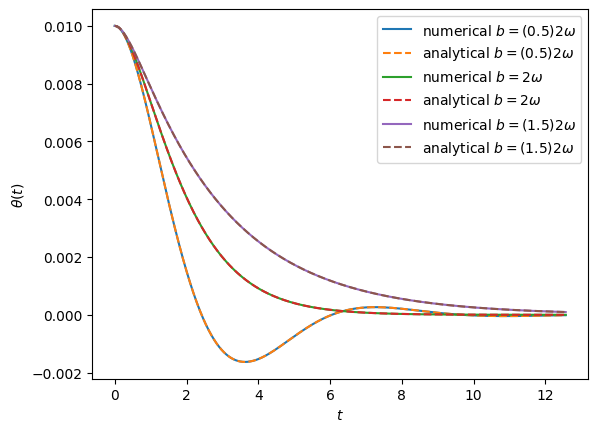

In [110]:
plt.plot(pendu_3.t, pendu_3.th, label ='numerical '+r'$b = (0.5) 2 \omega$')
underdamped_analytical = lambda th0, t, b, w: th0*np.exp(-b*t/2)*np.cos(np.sqrt(-b**2 + 4*w**2)*t/2)  + (th0*b/np.sqrt(-b**2 + 4*w**2))*np.exp(-b*t/2)*np.sin(np.sqrt(-b**2 + 4*w**2)*t/2)
plt.plot(pendu_3.t, underdamped_analytical(0.01, pendu_3.t, pendu_3.b, w), linestyle='dashed', label ='analytical '+r'$b = (0.5) 2 \omega$')

plt.plot(pendu_4.t, pendu_4.th, label ='numerical '+r'$b = 2 \omega$')
critdamped_analytical = lambda th0, t, b: th0*np.exp(-b*t/2)  + (th0*b/2)*t*np.exp(-b*t/2)
plt.plot(pendu_4.t, critdamped_analytical(0.01, pendu_4.t, pendu_4.b), linestyle='dashed', label ='analytical '+r'$b = 2 \omega$')

plt.plot(pendu_5.t, pendu_5.th, label ='numerical '+r'$b = (1.5) 2 \omega$') 

def overdamped_analytical(th0, t, b, w):
    lam1 = -b/2. + np.sqrt(b**2 - 4*w**2)/2
    lam2 = -b/2. - np.sqrt(b**2 - 4*w**2)/2

    return th0*lam2*np.exp(lam1*t)/(lam2 - lam1)  - th0*lam1*np.exp(lam2*t)/(lam2 - lam1)

plt.plot(pendu_5.t, overdamped_analytical(0.01, pendu_5.t, pendu_5.b, w), linestyle='dashed', label ='analytical '+r'$b = (1.5) 2 \omega$')

plt.xlabel(r'$t$')
plt.ylabel(r'$\theta(t)$')
plt.legend()
plt.show()

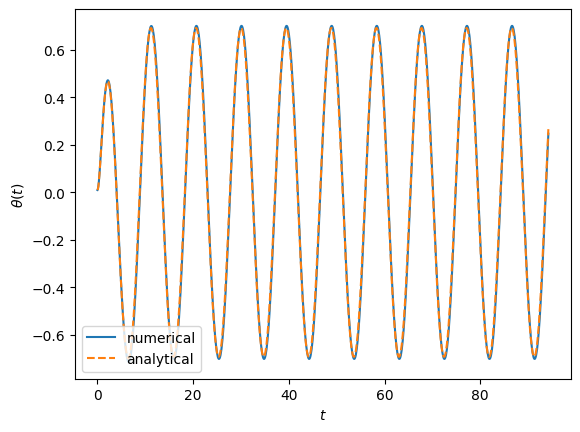

In [111]:
plt.plot(pendu_6.t, pendu_6.th, label ='numerical')

def critdamped_driven_analytical(th0, t, b, w, F, wD):
    A = F*(w**2 - wD**2)/((w**2 - wD**2)**2 + b**2*wD**2)
    B = b*wD*F/((w**2 - wD**2)**2 + b**2*wD**2)

    C1 = th0 - A
    C2 = C1*b/2 - B*wD

    return C1*np.exp(-b*t/2) + C2*t*np.exp(-b*t/2) + A*np.cos(wD*t) + B*np.sin(wD*t)
    
plt.plot(pendu_6.t, critdamped_driven_analytical(pendu_6.th[0], pendu_6.t, pendu_6.b, pendu_6.w, pendu_6.F, pendu_6.wext), linestyle='dashed', label ='analytical')

plt.xlabel(r'$t$')
plt.ylabel(r'$\theta(t)$')
plt.legend(loc=3)
plt.show()

## CHAOS

### Lyapunov Exponent

In [169]:
pendu_7 = pendulum(m, w, L, np.pi/6, 100*2*np.pi/(2/3), 0.5, 1.2, 2/3)

pendu_8 = pendulum(m, w, L, np.pi/6 + 0.001, 100*2*np.pi/(2/3), 0.5, 1.2, 2/3)

In [170]:
pendu_7.TE()
pendu_8.TE()

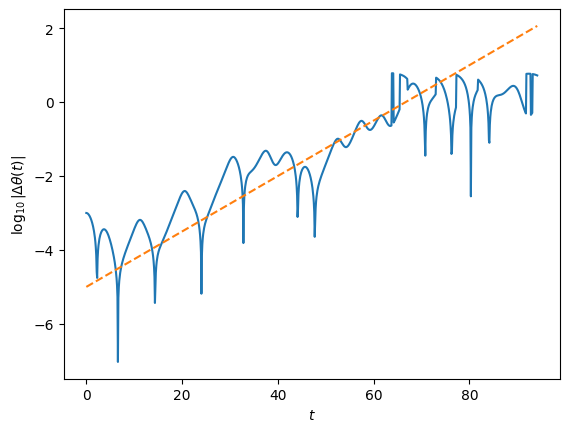

In [183]:
plt.plot(pendu_7.t[0:1000], np.log10(np.abs(pendu_8.th - pendu_7.th))[0:1000])
plt.plot(pendu_7.t[0:1000], 0.075*pendu_7.t[0:1000] - 5, linestyle='dashed')
plt.ylabel(r'$\log_{10}|\Delta \theta(t)|$')
plt.xlabel(r'$t$')
plt.show()

In [172]:
pendu_9 = pendulum(m, w, L, np.pi/4, 100*2*np.pi/(2/3), 0.5, 1.2, 2/3)

pendu_10 = pendulum(m, w, L, np.pi/4 + 0.001, 100*2*np.pi/(2/3), 0.5, 1.2, 2/3)

In [173]:
pendu_9.TE()
pendu_10.TE()

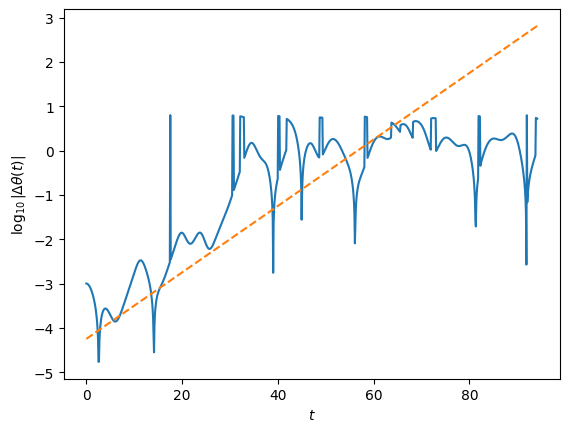

In [184]:
plt.plot(pendu_9.t[0:1000], np.log10(np.abs(pendu_9.th[0:1000] - pendu_10.th[0:1000])))
plt.plot(pendu_9.t[0:1000], 0.075*pendu_9.t[0:1000] - 4.25, linestyle='dashed')
plt.ylabel(r'$\log_{10}|\Delta \theta(t)|$')
plt.xlabel(r'$t$')
plt.show()

In [175]:
pendu_11 = pendulum(m, w, L, np.pi/3, 100*2*np.pi/(2/3), 0.5, 1.2, 2/3)

pendu_12 = pendulum(m, w, L, np.pi/3 + 0.001, 100*2*np.pi/(2/3), 0.5, 1.2, 2/3)

In [176]:
pendu_11.TE()
pendu_12.TE()

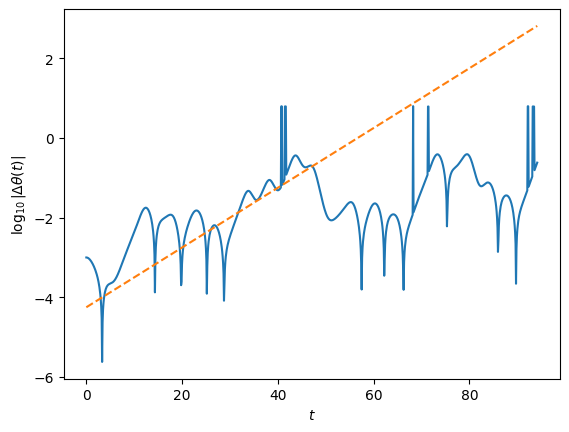

In [185]:
plt.plot(pendu_11.t[0:1000], np.log10(np.abs(pendu_11.th[0:1000] - pendu_12.th[0:1000])))
plt.plot(pendu_11.t[0:1000], 0.075*pendu_11.t[0:1000] - 4.25, linestyle='dashed')
plt.ylabel(r'$\log_{10}|\Delta \theta(t)|$')
plt.xlabel(r'$t$')
plt.show()

So can infer that the Lyapunov exponent at this driving force + frequency + damping regime is $\lambda  = 0.075$

### Poincare Sections

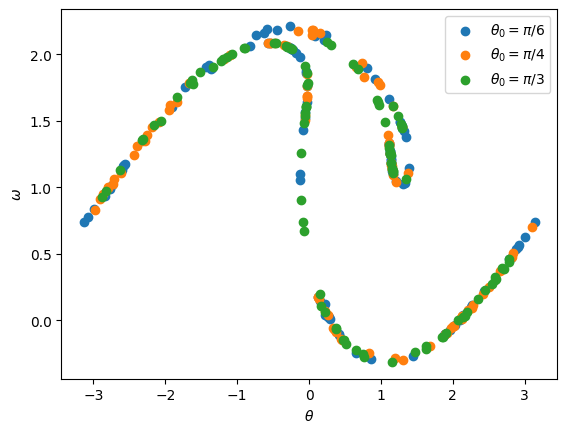

In [181]:
plt.scatter(pendu_7.th[100::100], pendu_7.v[100::100], label =r'$\theta_0 = \pi/6$')
plt.scatter(pendu_9.th[100::100], pendu_9.v[100::100], label =r'$\theta_0 = \pi/4$')
plt.scatter(pendu_11.th[100::100], pendu_11.v[100::100], label =r'$\theta_0 = \pi/3$')
plt.xlabel(r'$\theta$')
plt.ylabel(r'$\omega$')
plt.legend()
plt.show()

### Bifurcation Diagram

In [198]:
driving_forces = np.linspace(1.35,1.5, int((1.5-1.35)/0.001 + 1))
bifurc_x_axis = np.empty(0)
bifurc_y_axis = np.empty(0)
for i in range(0, len(driving_forces)):
    pendu_13 = pendulum(m, w, L, 0.01, 400*2*np.pi/(2/3), 0.5, driving_forces[i], 2/3)
    pendu_13.TE()
    bifurc_y_axis = np.concatenate((bifurc_y_axis, pendu_13.th[30000::100]) )
    bifurc_x_axis = np.concatenate((bifurc_x_axis, np.repeat(driving_forces[i], len(pendu_13.th[30000::100]))) )
    print(i)




0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149


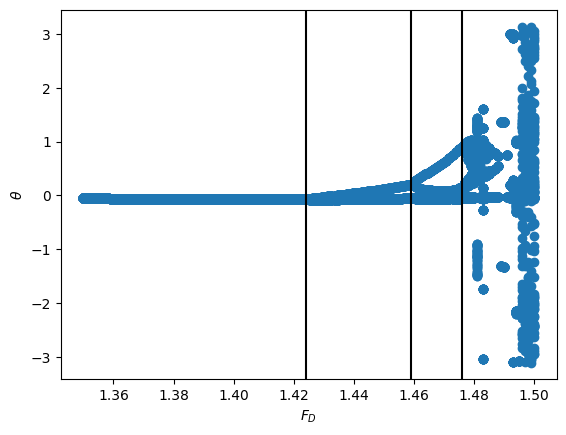

In [209]:
plt.scatter(bifurc_x_axis, bifurc_y_axis)
plt.xlabel(r'$F_D$')
plt.ylabel(r'$\theta$')
plt.axvline(x = 1.424, c='black')
plt.axvline(x = 1.459, c='black')
plt.axvline(x = 1.476, c='black')
plt.show()

In [210]:
(1.476 - 1.459)/(1.459 - 1.424)

0.485714285714281

The true Feigenbaum Delta as the number of periods reaches infinity is 4.669